In [0]:

from pyspark.sql import functions as F
import pandas as pd
import numpy as np

df = spark.table("workspace.default.freddie_model_split")

features = [
    "time_months", "event",
    "fico", "orig_ltv",
    "orig_interest_rate", "log_orig_upb",
    "num_borrowers", "relief_refinance_flag"
]

train_pd = (
    df.filter(F.col("split") == "train")
      .select(*features)
      .toPandas()
)

# Training-only median imputation for FICO
fico_median = train_pd["fico"].median()
train_pd["fico"] = train_pd["fico"].fillna(fico_median)

# Scale predictors for interpretable hazard ratios
train_pd["fico_per_20"] = train_pd["fico"] / 20
train_pd["ltv_per_10"] = train_pd["orig_ltv"] / 10

train_pd["relief_refinance"] = (
    train_pd["relief_refinance_flag"] == "Y"
).astype(int)

cox_cols = [
    "time_months", "event",
    "fico_per_20", "ltv_per_10",
    "orig_interest_rate", "log_orig_upb",
    "num_borrowers", "relief_refinance"
]

cox_train = train_pd[cox_cols].copy()

print("Training loans:", len(cox_train))
print("Events:", cox_train["event"].sum())
print("Missing:", cox_train.isna().sum().sum())


Training loans: 34975
Events: 2048
Missing: 0


In [0]:
%pip install lifelines

Looking in indexes: [REDACTED]
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4119 sha256=b492913c4e662f4ca82ff00b3abea2845638639064c244fd5d4645e8f145e104
  Stored in directory: /home/spark-9368633d-c00b-4d4c-8bcc-be/.cache/pip/wheels/64/a2/a1/d7253b3fe88c7038ec3ef6a2cb2cedbf927b138b8077301f4d
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [lifelines]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
from lifelines import CoxPHFitter


cph = CoxPHFitter(penalizer=0.01)

cph.fit(
    cox_train,
    duration_col="time_months",
    event_col="event",
    robust=True
)

display(
    cph.summary[
        [
            "coef", "exp(coef)",
            "exp(coef) lower 95%",
            "exp(coef) upper 95%",
            "p"
        ]
    ]
)

print("Training concordance:", cph.concordance_index_)


coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
-0.20399576083901308,0.8154658280708901,0.8034729427034568,0.8276377229503954,2.159435474372824E-160
0.07458765106203079,1.0774397781243747,1.0514267922393394,1.104096342278149,2.2087638681987247E-9
0.4620491646125074,1.5873233414442267,1.4551804636444374,1.7314659269019088,2.0336858264170684E-25
0.45443590649827925,1.575284524594241,1.4668686252391079,1.6917134164087817,8.36669336243835E-36
-0.49555892988921996,0.6092302950946599,0.5651547944101724,0.6567431721931893,2.9051104803610365E-38
-0.07144589850924779,0.9310466472438887,0.7782703841329475,1.1138132415379276,0.43464317533094843


Training concordance: 0.7269559847298831


In [0]:

from lifelines.utils import concordance_index

# Make sure covariate names are correct
display(
    cph.summary[
        ["exp(coef)", "exp(coef) lower 95%",
         "exp(coef) upper 95%", "p"]
    ].reset_index()
)

# Load validation data
val_pd = (
    df.filter(F.col("split") == "validation")
      .select(*features)
      .toPandas()
)

# Apply TRAINING median, not validation median
val_pd["fico"] = val_pd["fico"].fillna(fico_median)

# Same transformations as training
val_pd["fico_per_20"] = val_pd["fico"] / 20
val_pd["ltv_per_10"] = val_pd["orig_ltv"] / 10

val_pd["relief_refinance"] = (
    val_pd["relief_refinance_flag"] == "Y"
).astype(int)

cox_val = val_pd[cox_cols].copy()

# Predict relative hazard
val_risk = cph.predict_partial_hazard(
    cox_val.drop(columns=["time_months", "event"])
)

# Larger risk means shorter expected event time
val_cindex = concordance_index(
    cox_val["time_months"],
    -val_risk.to_numpy().ravel(),
    cox_val["event"]
)

print(f"Training C-index:   {cph.concordance_index_:.4f}")
print(f"Validation C-index: {val_cindex:.4f}")
print(f"Validation loans:   {len(cox_val):,}")
print(f"Validation events:  {cox_val['event'].sum():,}")


covariate,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
fico_per_20,0.8154658280708901,0.8034729427034568,0.8276377229503954,2.159435474372824E-160
ltv_per_10,1.0774397781243747,1.0514267922393394,1.104096342278149,2.2087638681987247E-9
orig_interest_rate,1.5873233414442267,1.4551804636444374,1.7314659269019088,2.0336858264170684E-25
log_orig_upb,1.575284524594241,1.4668686252391079,1.6917134164087817,8.36669336243835E-36
num_borrowers,0.6092302950946599,0.5651547944101724,0.6567431721931893,2.9051104803610365E-38
relief_refinance,0.9310466472438887,0.7782703841329475,1.1138132415379276,0.43464317533094843


Training C-index:   0.7270
Validation C-index: 0.7306
Validation loans:   7,495
Validation events:  439


In [0]:
#PH Assumption Test


from lifelines.statistics import proportional_hazard_test

# Refit for PH diagnostics and standard-error sensitivity
cph_ph = CoxPHFitter(penalizer=0.01)

cph_ph.fit(
    cox_train,
    duration_col="time_months",
    event_col="event",
    robust=False
)

# Schoenfeld residual-based PH test
ph_test = proportional_hazard_test(
    cph_ph,
    cox_train,
    time_transform="rank"
)

# Display results
ph_results = ph_test.summary.reset_index()

display(
    ph_results.sort_values("p")
)

print("Original training C-index:",
      round(cph.concordance_index_, 4))

print("Refitted training C-index:",
      round(cph_ph.concordance_index_, 4))


index,test_statistic,p,-log2(p)
fico_per_20,14.044016663069549,1.7858110602075305E-4,12.451132928945187
ltv_per_10,3.0178825394613513,0.08235092527958894,3.602071329880471
relief_refinance,0.9309032240772964,0.3346283328080073,1.579368492095975
orig_interest_rate,0.8174895595861685,0.36591518348095675,1.450418814006203
log_orig_upb,0.6233349291921979,0.4298106984901926,1.2182267013104724
num_borrowers,0.22267624146928355,0.6370082790970144,0.6506159718020397


Original training C-index: 0.727
Refitted training C-index: 0.727



   Bootstrapping lowess lines. May take a moment...





1. Variable 'fico_per_20' failed the non-proportional test: p-value is 0.0002.



[[<Axes: xlabel='rank-transformed time\n(p=0.0002)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0007)'>]]

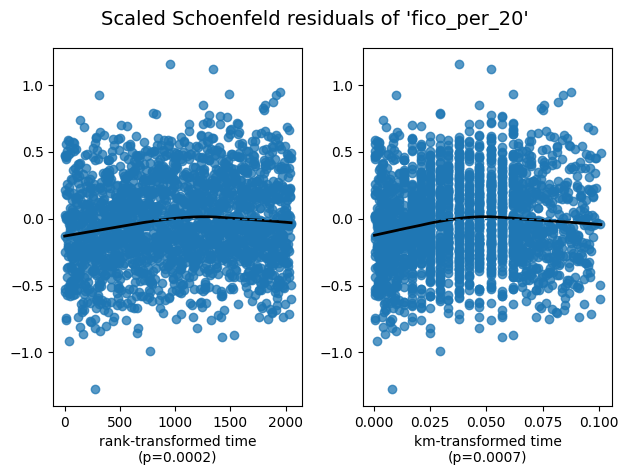

In [0]:

# Visualize the PH violation for FICO
cph_ph.check_assumptions(
    cox_train,
    columns=["fico_per_20"],
    p_value_threshold=0.05,
    show_plots=True,
    advice=False,
    plot_n_bootstraps=0
)


XGBoost 

In [0]:
%pip install xgboost

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.2/57.2 MB 177.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 172.7 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:

import xgboost as xgb
import numpy as np
from lifelines.utils import concordance_index

# Use the same six predictors as Cox
x_cols = [
    "fico_per_20",
    "ltv_per_10",
    "orig_interest_rate",
    "log_orig_upb",
    "num_borrowers",
    "relief_refinance"
]

X_train = cox_train[x_cols].copy()
X_val = cox_val[x_cols].copy()

# XGBoost survival:cox label convention:
# Positive time = observed event
# Negative time = right-censored
y_train = np.where(
    cox_train["event"] == 1,
    cox_train["time_months"],
    -cox_train["time_months"]
).astype(float)

y_val = np.where(
    cox_val["event"] == 1,
    cox_val["time_months"],
    -cox_val["time_months"]
).astype(float)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("XGBoost version:", xgb.__version__)


Train: (34975, 6)
Validation: (7495, 6)
XGBoost version: 3.4.1


In [0]:

model_xgb = xgb.XGBRegressor(
    objective="survival:cox",
    eval_metric="cox-nloglik",
    tree_method="hist",

    n_estimators=800,
    learning_rate=0.03,
    max_depth=2,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.9,
    reg_lambda=10,

    early_stopping_rounds=40,
    random_state=42,
    n_jobs=4
)

model_xgb.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("Best iteration:", model_xgb.best_iteration)
print("Best validation score:", model_xgb.best_score)


Best iteration: 437
Best validation score: 8.048632890928141


In [0]:

# Higher XGBoost output = higher hazard
risk_train = model_xgb.predict(X_train)
risk_val = model_xgb.predict(X_val)

xgb_train_c = concordance_index(
    cox_train["time_months"],
    -risk_train,
    cox_train["event"]
)

xgb_val_c = concordance_index(
    cox_val["time_months"],
    -risk_val,
    cox_val["event"]
)

print("=== Cox vs XGBoost Cox ===")
print(f"Cox train:       {cph.concordance_index_:.4f}")
print(f"Cox validation:  {val_cindex:.4f}")
print(f"XGB train:       {xgb_train_c:.4f}")
print(f"XGB validation:  {xgb_val_c:.4f}")


=== Cox vs XGBoost Cox ===
Cox train:       0.7270
Cox validation:  0.7306
XGB train:       0.7423
XGB validation:  0.7369


feature,mean_abs_shap
fico_per_20,0.5743464
num_borrowers,0.30553526
log_orig_upb,0.24532916
orig_interest_rate,0.18390055
ltv_per_10,0.14548013
relief_refinance,3.7444074E-4


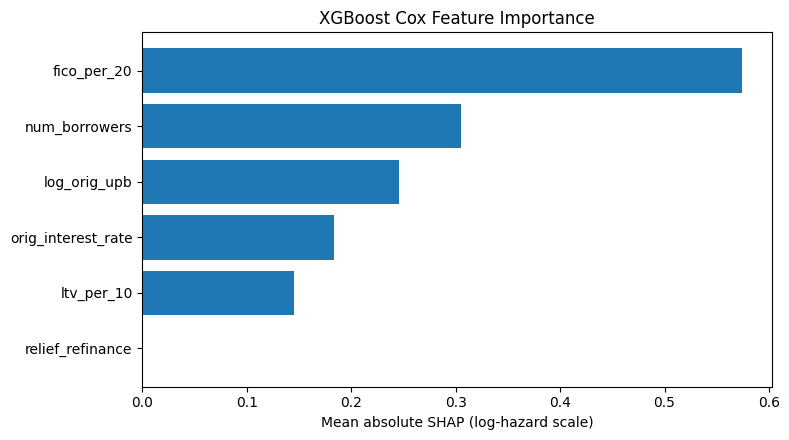

In [0]:


import matplotlib.pyplot as plt
import xgboost as xgb

# Sample validation observations for interpretation
X_shap = X_val.sample(
    n=min(1500, len(X_val)),
    random_state=42
)

dm = xgb.DMatrix(X_shap)

# Use the best iteration from early stopping
contribs = model_xgb.get_booster().predict(
    dm,
    pred_contribs=True,
    iteration_range=(0, model_xgb.best_iteration + 1)
)

# Last column is the baseline contribution
shap_values = contribs[:, :-1]

importance = pd.DataFrame({
    "feature": X_shap.columns,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(importance)

plt.figure(figsize=(8, 4.5))
plt.barh(
    importance["feature"][::-1],
    importance["mean_abs_shap"][::-1]
)
plt.xlabel("Mean absolute SHAP (log-hazard scale)")
plt.title("XGBoost Cox Feature Importance")
plt.tight_layout()
plt.show()


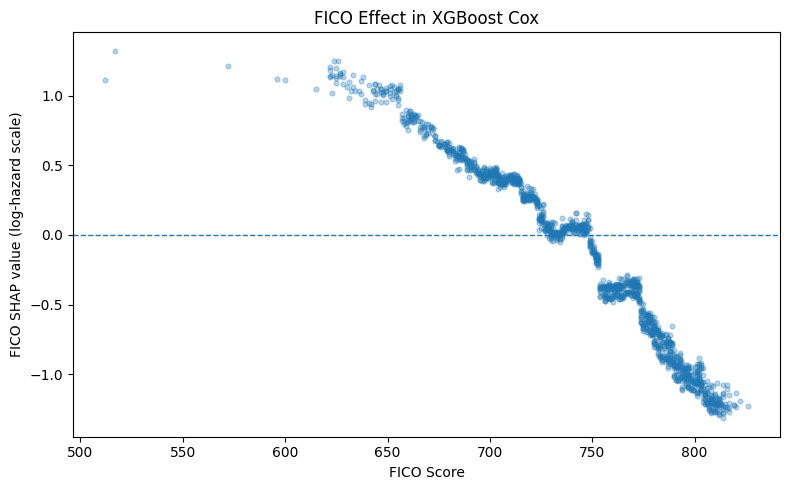

In [0]:

fico_idx = list(X_shap.columns).index("fico_per_20")

plt.figure(figsize=(8, 5))

plt.scatter(
    X_shap["fico_per_20"] * 20,
    shap_values[:, fico_idx],
    alpha=0.3,
    s=12
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("FICO Score")
plt.ylabel("FICO SHAP value (log-hazard scale)")
plt.title("FICO Effect in XGBoost Cox")
plt.tight_layout()
plt.show()


In [0]:

booster = model_xgb.get_booster()

split_counts = booster.get_score(
    importance_type="weight"
)

print("Number of tree splits by feature:")

for feature in X_train.columns:
    print(f"{feature}: {split_counts.get(feature, 0)}")


Number of tree splits by feature:
fico_per_20: 408.0
ltv_per_10: 221.0
orig_interest_rate: 205.0
log_orig_upb: 421.0
num_borrowers: 131.0
relief_refinance: 5.0


In [0]:

raw_margin = booster.predict(
    dm,
    output_margin=True,
    iteration_range=(0, model_xgb.best_iteration + 1)
)

print(
    "Max SHAP reconstruction error:",
    np.max(np.abs(contribs.sum(axis=1) - raw_margin))
)


Max SHAP reconstruction error: 2.6226044e-06


In [0]:


df = spark.table("workspace.default.freddie_model_split")

display(
    df.filter(F.col("split") == "validation")
    .agg(*[
        F.sum(
            (
                (F.col("event_type") == 0) &
                (F.col("time_months") <= h)
            ).cast("int")
        ).alias(f"censored_by_{h}m")
        for h in [12, 24, 36]
    ])
)


censored_by_12m,censored_by_24m,censored_by_36m
0,0,0


In [0]:


from sklearn.metrics import roc_auc_score

features = [
    "time_months", "event", "fico",
    "orig_ltv", "orig_interest_rate",
    "log_orig_upb", "num_borrowers",
    "relief_refinance_flag"
]

val = (
    df.filter(F.col("split") == "validation")
    .select("loan_id", "event_type", *features)
    .orderBy("loan_id")
    .toPandas()
)

# Apply the same preprocessing as training
val["fico"] = val["fico"].fillna(fico_median)
val["fico_per_20"] = val["fico"] / 20
val["ltv_per_10"] = val["orig_ltv"] / 10
val["relief_refinance"] = (
    val["relief_refinance_flag"] == "Y"
).astype(int)

# Scores aligned to the same validation rows
cox_scores = cph.predict_partial_hazard(
    val[cox_cols].drop(
        columns=["time_months", "event"]
    )
).to_numpy().ravel()

xgb_scores = model_xgb.predict(val[x_cols])

results = []

for h in [12, 24, 36]:

    early_censored = (
        (val["event_type"] == 0) &
        (val["time_months"] <= h)
    ).sum()

    if early_censored > 0:
        print(
            f"{h}m: {early_censored} early censored "
            "loans; use IPCW AUC instead."
        )
        continue

    y = (
        (val["event_type"] == 1) &
        (val["time_months"] <= h)
    ).astype(int)

    results.append({
        "horizon": h,
        "n_cases": int(y.sum()),
        "cox_auc": roc_auc_score(y, cox_scores),
        "xgb_auc": roc_auc_score(y, xgb_scores)
    })

auc_results = pd.DataFrame(results)
display(auc_results)


horizon,n_cases,cox_auc,xgb_auc
12,24,0.7446794271181905,0.7473675991612011
24,64,0.7411582391333603,0.7552146413672454
36,253,0.7174071320896004,0.7248652731704496
